# Diabetes Prediction Using Random Forest

## Project Overview

This project uses Machine Learning to predict whether a person is likely to have diabetes based on medical measurements.

The project uses the Random Forest Classifier.

## Objectives

- Load and understand the diabetes dataset.
- Clean and preprocess the data.
- Perform Exploratory Data Analysis (EDA).
- Train a Random Forest classification model.
- Evaluate model performance.
- Visualize the results.
- Identify important features.
- Save the trained model for future use.

**Note:** This is an educational Machine Learning project. It is not a medical diagnostic system.

In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    RocCurveDisplay
)

# Display settings
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

# Create folders if they do not exist
os.makedirs("images", exist_ok=True)
os.makedirs("models", exist_ok=True)

print("Libraries imported successfully!")

Libraries imported successfully!


## 1. Dataset Information

We are using the Pima Indians Diabetes Dataset.

The dataset contains 768 records and 9 columns.

### Dataset Features

1. Pregnancies: Number of times pregnant.
2. Glucose: Plasma glucose concentration.
3. BloodPressure: Diastolic blood pressure.
4. SkinThickness: Triceps skin fold thickness.
5. Insulin: 2-Hour serum insulin.
6. BMI: Body Mass Index.
7. DiabetesPedigreeFunction: Diabetes pedigree function.
8. Age: Age of the person.
9. Outcome: Target variable.

### Target Variable

- 0 = No diabetes
- 1 = Diabetes

Our goal is to predict the Outcome using the other eight features.

In [2]:
data = pd.read_csv("data/diabetes.csv")

print("Dataset loaded successfully!")

display(data.head())

Dataset loaded successfully!


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
print("Dataset Shape:", data.shape)

print("\nColumn Names:")
print(data.columns.tolist())

print("\nDataset Information:")
data.info()

print("\nStatistical Summary:")
display(data.describe())

Dataset Shape: (768, 9)

Column Names:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Statistical Summary:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


## 2. Data Cleaning and Preprocessing

Before training our model, we need to clean the dataset.

Some measurements contain zero values that are not medically meaningful in this dataset.

We will treat zero values in these columns as missing values:

- Glucose
- BloodPressure
- SkinThickness
- Insulin
- BMI

We will not replace zero values in Pregnancies because zero pregnancies is valid.

We will use median imputation to fill missing values.

**Important:** Median imputation will be performed inside a Machine Learning Pipeline after splitting the data. This prevents data leakage.

In [4]:
print("Missing Values Before Cleaning:")
print(data.isnull().sum())

print("\nDuplicate Rows:", data.duplicated().sum())

print("\nOutcome Distribution:")
print(data["Outcome"].value_counts())

Missing Values Before Cleaning:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Duplicate Rows: 0

Outcome Distribution:
Outcome
0    500
1    268
Name: count, dtype: int64


In [5]:
data = data.copy()

# Remove unnecessary unnamed columns
data = data.loc[:, ~data.columns.str.contains("^Unnamed")]

# Remove duplicate rows
data = data.drop_duplicates()

# Convert columns to numeric
for column in data.columns:
    data[column] = pd.to_numeric(data[column], errors="coerce")

# Check required columns
expected_columns = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome"
]

missing_columns = set(expected_columns) - set(data.columns)

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

# Keep only valid target values
data = data.dropna(subset=["Outcome"])
data = data[data["Outcome"].isin([0, 1])].copy()
data["Outcome"] = data["Outcome"].astype(int)

# Replace medically invalid zero measurements with NaN
zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

data[zero_columns] = data[zero_columns].replace(0, np.nan)

print("Data cleaning completed!")

print("\nDataset Shape:", data.shape)

print("\nMissing Values After Cleaning:")
print(data.isnull().sum())

Data cleaning completed!

Dataset Shape: (768, 9)

Missing Values After Cleaning:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


## 3. Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand the dataset through charts and statistics.

In this section, we will study:

1. Diabetes outcome distribution.
2. Age distribution.
3. Glucose distribution.
4. BMI distribution.
5. Correlation between features.

These visualizations help us understand patterns in the data before training the model.

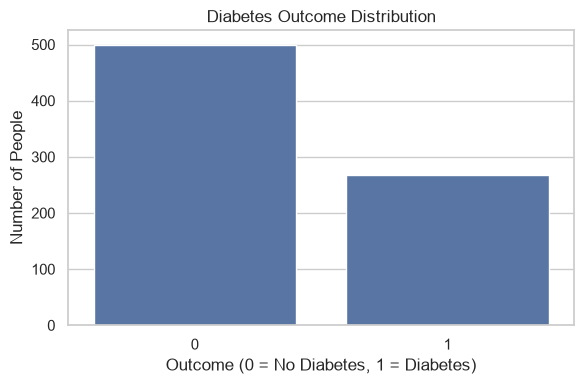

In [6]:
plt.figure(figsize=(6, 4))

sns.countplot(data=data, x="Outcome")

plt.title("Diabetes Outcome Distribution")
plt.xlabel("Outcome (0 = No Diabetes, 1 = Diabetes)")
plt.ylabel("Number of People")

plt.tight_layout()
plt.savefig("images/diabetes_distribution.png")
plt.show()

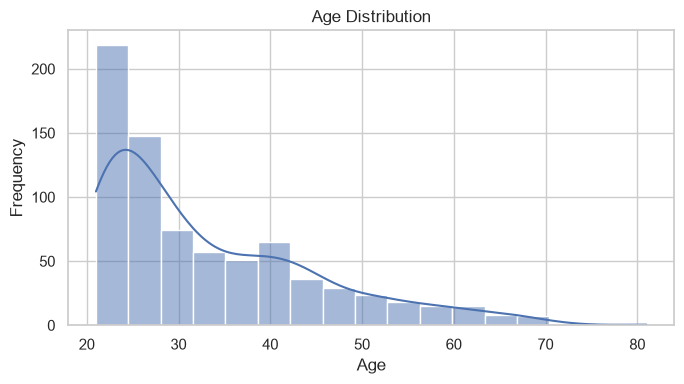

In [7]:
plt.figure(figsize=(7, 4))

sns.histplot(data=data, x="Age", kde=True)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.tight_layout()
plt.savefig("images/age_distribution.png")
plt.show()

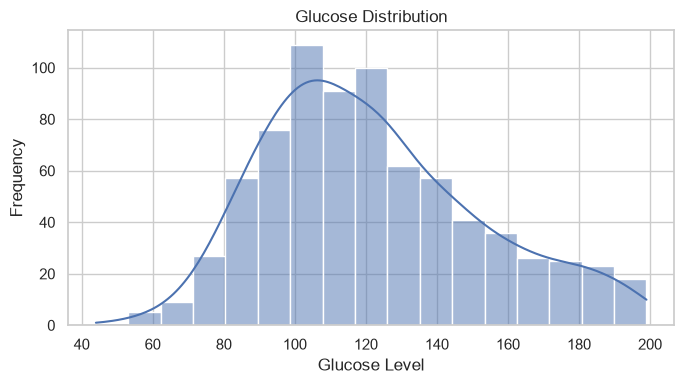

In [8]:
plt.figure(figsize=(7, 4))

sns.histplot(data=data, x="Glucose", kde=True)

plt.title("Glucose Distribution")
plt.xlabel("Glucose Level")
plt.ylabel("Frequency")

plt.tight_layout()
plt.savefig("images/glucose_distribution.png")
plt.show()

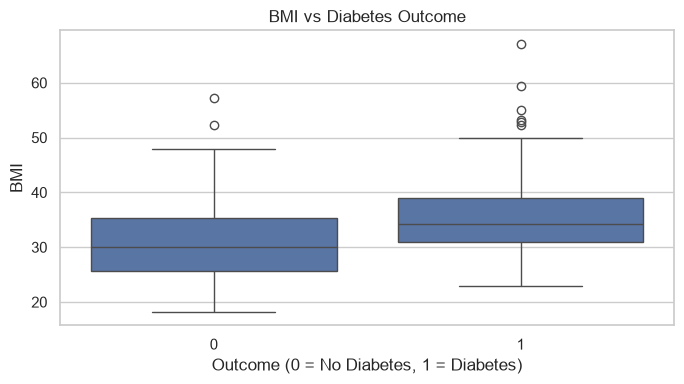

In [9]:
plt.figure(figsize=(7, 4))

sns.boxplot(data=data, x="Outcome", y="BMI")

plt.title("BMI vs Diabetes Outcome")
plt.xlabel("Outcome (0 = No Diabetes, 1 = Diabetes)")
plt.ylabel("BMI")

plt.tight_layout()
plt.savefig("images/bmi_vs_outcome.png")
plt.show()

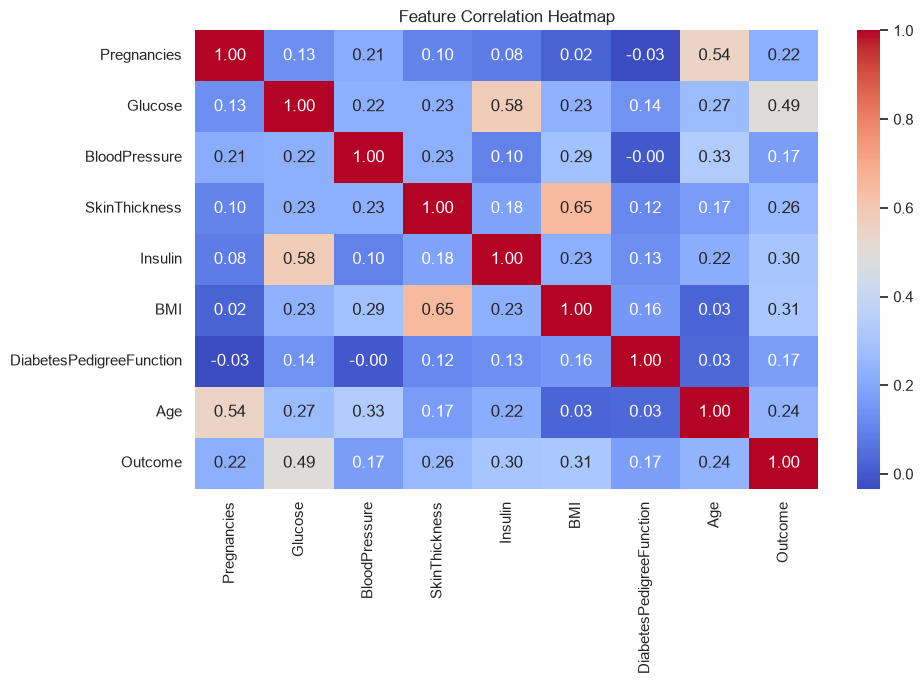

In [10]:
plt.figure(figsize=(10, 7))

correlation = data.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")

plt.tight_layout()
plt.savefig("images/correlation_heatmap.png")
plt.show()

## 4. Preparing Data for Model Training

Now we will separate the dataset into two parts.

### Features (X)

The eight input columns used to make predictions.

### Target (y)

The Outcome column that we want to predict.

### Train-Test Split

We will divide the dataset into:

- 80% training data.
- 20% testing data.

We will use stratify=y to maintain a similar proportion of both outcome classes in the training and testing sets.

We will also use random_state=42 to make the split reproducible.

In [11]:
X = data.drop("Outcome", axis=1)

y = data["Outcome"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (768, 8)
Target Shape: (768,)


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True))

Training Features: (614, 8)
Testing Features: (154, 8)

Training Target Distribution:
Outcome
0    0.651466
1    0.348534
Name: proportion, dtype: float64

Testing Target Distribution:
Outcome
0    0.649351
1    0.350649
Name: proportion, dtype: float64


## 5. Building the Random Forest Model

We will use the Random Forest Classifier.

### What is Random Forest?

Random Forest is a Machine Learning algorithm that uses multiple decision trees to make predictions.

Each tree makes a prediction, and the final prediction is decided through voting.

### Why Random Forest?

- It can learn complex patterns.
- It works with numerical features.
- It can estimate feature importance.
- It combines multiple decision trees.

### Model Preprocessing

We will create a Pipeline containing:

1. SimpleImputer: Fills missing values using the median.
2. RandomForestClassifier: Trains the Random Forest model.

The imputer learns median values from the training data only.

Random Forest does not require feature scaling, so we will not use StandardScaler.

In [13]:
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),

    ("random_forest", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    ))
])

print("Random Forest model created successfully!")

Random Forest model created successfully!


## 6. Model Training

Now we will train our Random Forest model using the training dataset.

The model will learn patterns from the input features and their corresponding diabetes outcomes.

In [14]:
model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


## 7. Making Predictions

After training, we will use the testing dataset to make predictions.

The model will predict:

- 0 = No diabetes
- 1 = Diabetes

We will also calculate prediction probabilities for ROC-AUC evaluation.

In [15]:
y_pred = model.predict(X_test)

y_prob = model.predict_proba(X_test)[:, 1]

print("Predictions generated successfully!")

print("\nFirst 10 Actual Values:")
print(y_test.head(10).values)

print("\nFirst 10 Predicted Values:")
print(y_pred[:10])

Predictions generated successfully!

First 10 Actual Values:
[0 0 0 1 0 0 1 1 0 0]

First 10 Predicted Values:
[1 0 0 0 0 0 1 1 0 1]


## 8. Model Evaluation

We will evaluate the Random Forest model using the following metrics.

### 1. Accuracy

Measures the percentage of all predictions that are correct.

### 2. Precision

Measures how many predicted diabetes cases were actually diabetes cases.

### 3. Recall

Measures how many actual diabetes cases the model successfully identified.

### 4. F1-Score

Combines precision and recall into one score.

### 5. ROC-AUC

Measures how well the model distinguishes between the two classes across different classification thresholds.

Recall is particularly important to examine in this healthcare-related classification task because missed positive cases matter.

In [17]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred, zero_division=0)

recall = recall_score(y_test, y_pred, zero_division=0)

f1 = f1_score(y_test, y_pred, zero_division=0)

roc_auc = roc_auc_score(y_test, y_prob)

print("Random Forest Evaluation Results")

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

Random Forest Evaluation Results
Accuracy:  0.7403
Precision: 0.6167
Recall:    0.6852
F1 Score:  0.6491
ROC-AUC:   0.8294


In [18]:
print("Classification Report:\n")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No Diabetes", "Diabetes"],
        zero_division=0
    )
)

Classification Report:

              precision    recall  f1-score   support

 No Diabetes       0.82      0.77      0.79       100
    Diabetes       0.62      0.69      0.65        54

    accuracy                           0.74       154
   macro avg       0.72      0.73      0.72       154
weighted avg       0.75      0.74      0.74       154



## 9. Confusion Matrix

A confusion matrix shows correct and incorrect predictions.

It contains four important values:

- True Negative: Correctly predicted no diabetes.
- True Positive: Correctly predicted diabetes.
- False Positive: Predicted diabetes, but actual outcome was no diabetes.
- False Negative: Predicted no diabetes, but actual outcome was diabetes.

A confusion matrix helps us understand the types of mistakes made by the model.

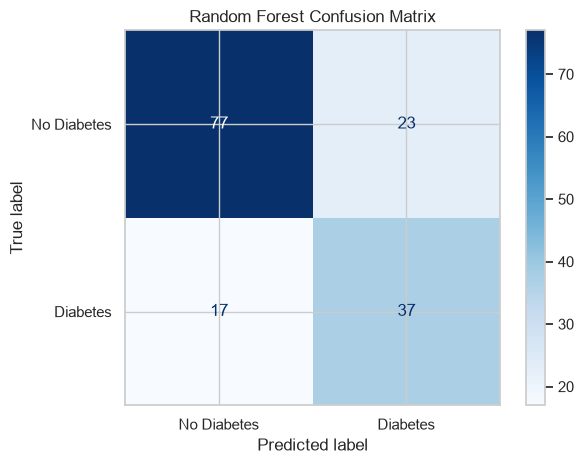

In [23]:
cm = confusion_matrix(y_test, y_pred)

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Diabetes", "Diabetes"]
)

cm_display.plot(cmap="Blues", values_format="d")

plt.title("Random Forest Confusion Matrix")

plt.tight_layout()
plt.savefig("images/confusion_matrix.png")
plt.show()

## 10. ROC Curve

The ROC curve shows the relationship between:

- True Positive Rate.
- False Positive Rate.

The ROC-AUC score summarizes the model's ability to distinguish between the two classes.

A higher ROC-AUC generally indicates better class separation.

We will visualize the ROC curve for our Random Forest model.

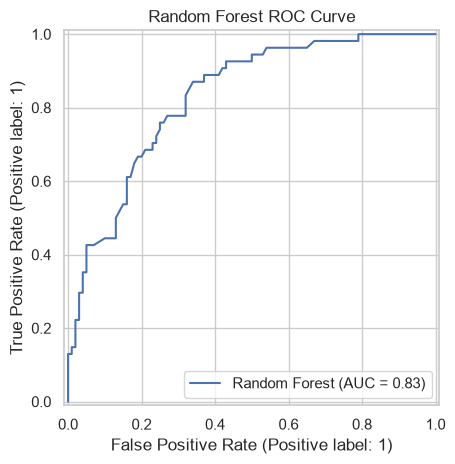

In [24]:
RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    name="Random Forest"
)

plt.title("Random Forest ROC Curve")

plt.tight_layout()
plt.savefig("images/roc_curve.png")
plt.show()

## 11. Cross-Validation

Cross-validation helps us understand how consistently our model performs on different portions of the training data.

We will use 5-fold cross-validation.

The training dataset is divided into five parts.

The model is trained and evaluated five times, using a different part for validation each time.

We will use ROC-AUC as the evaluation metric.

Cross-validation is performed only on the training dataset. The test dataset remains separate for final evaluation.

In [25]:
cv_scores = cross_val_score(
    model,
    X_train,
    y_train,
    cv=5,
    scoring="roc_auc"
)

print("Cross-Validation ROC-AUC Scores:")
print(cv_scores)

print("\nAverage Cross-Validation ROC-AUC:")
print(round(cv_scores.mean(), 4))

print("\nStandard Deviation:")
print(round(cv_scores.std(), 4))

Cross-Validation ROC-AUC Scores:
[0.79651163 0.85465116 0.7994186  0.82761628 0.83050595]

Average Cross-Validation ROC-AUC:
0.8217

Standard Deviation:
0.0216


## 12. Feature Importance

Feature importance helps us understand which input features contributed most to the Random Forest's predictions.

For example:

- Glucose
- BMI
- Age
- Insulin

The model calculates an importance score for each feature.

A higher score means the feature was more influential in the model's tree-based splits.

**Important:** Feature importance does not prove that a feature causes diabetes.

In [29]:
random_forest = model.named_steps["random_forest"]

importance = random_forest.feature_importances_

feature_data = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance
})

feature_data = feature_data.sort_values(
    by="Importance",
    ascending=False
)

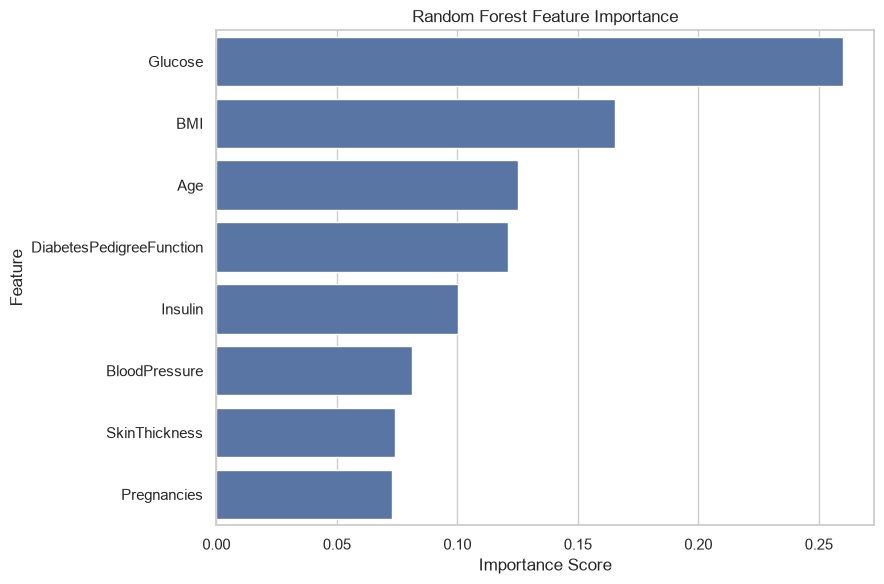

In [30]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=feature_data,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Feature")

plt.tight_layout()
plt.savefig("images/feature_importance.png")
plt.show()

## 13. Prediction for a New Patient

Now we will test our trained model using a sample patient.

We will provide eight input measurements.

The model will predict:

- 0 = No diabetes
- 1 = Diabetes

We will also display the model's estimated probability for the diabetes class.

This is only an educational demonstration. The result is not a medical diagnosis.

In [32]:
new_patient = pd.DataFrame([{
    "Pregnancies": 2,
    "Glucose": 120,
    "BloodPressure": 70,
    "SkinThickness": 25,
    "Insulin": 80,
    "BMI": 28.5,
    "DiabetesPedigreeFunction": 0.45,
    "Age": 30
}])

prediction = model.predict(new_patient)[0]

probability = model.predict_proba(new_patient)[0][1]

print("New Patient Prediction")

if prediction == 1:
    print("Predicted Outcome: Diabetes")
else:
    print("Predicted Outcome: No Diabetes")

print(f"Estimated Diabetes Probability: {probability:.2%}")

print("\nNote: This is not a medical diagnosis.")

New Patient Prediction
Predicted Outcome: No Diabetes
Estimated Diabetes Probability: 22.33%

Note: This is not a medical diagnosis.


In [33]:
model_path = "models/diabetes_random_forest.joblib"

joblib.dump(model, model_path)

print("Model saved successfully!")
print("Saved Location:", model_path)

Model saved successfully!
Saved Location: models/diabetes_random_forest.joblib


In [34]:
loaded_model = joblib.load(
    "models/diabetes_random_forest.joblib"
)

loaded_prediction = loaded_model.predict(new_patient)[0]

print("Saved model loaded successfully!")

print("Prediction from loaded model:", loaded_prediction)

print(
    "Original prediction:", prediction
)

if loaded_prediction == prediction:
    print("Model verification successful!")
else:
    print("Model verification failed!")

Saved model loaded successfully!
Prediction from loaded model: 0
Original prediction: 0
Model verification successful!


## 15. Project Conclusion

In this project, we developed a Diabetes Prediction system using the Random Forest Classifier.

### Work Completed

- Loaded and explored the diabetes dataset.
- Cleaned invalid zero measurements.
- Handled missing values using median imputation.
- Performed Exploratory Data Analysis.
- Created data visualizations.
- Split the dataset into training and testing sets.
- Built and trained a Random Forest model.
- Evaluated the model using multiple performance metrics.
- Created a confusion matrix and ROC curve.
- Performed 5-fold cross-validation.
- Analyzed feature importance.
- Tested the model using a sample patient.
- Saved and loaded the trained model using Joblib.

### Learning Outcomes

This project demonstrates practical knowledge of:

- Python Programming
- Data Cleaning
- Data Preprocessing
- Exploratory Data Analysis
- Random Forest Classification
- Model Evaluation
- Data Visualization
- Model Saving and Loading

### Final Note

This project is intended for educational purposes only. It must not be used to diagnose diabetes or replace professional medical advice.